<a href="https://colab.research.google.com/github/JustGeoCoder/Growth_Rate/blob/main/NDVI_Change_Detection_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -upgrade -pre xee
!pip install -U geemap

In [4]:
import ee
import geemap

In [ ]:
ee.Authenticate()
ee.Initialize(project = 'graphite-space-457522-v1')


In [ ]:
map = geemap.Map()
map

In [8]:
roi = map.draw_last_feature.geometry()

In [9]:
def cloud_mask(img):
  qa = img.select('QA60')
  cloud = qa.bitwiseAnd(1<<10).eq(0)
  cirrus = qa.bitwiseAnd(1<<11).eq(0)
  mask = cloud.Or(cirrus)
  return img.updateMask(mask).multiply(0.0001).copyProperties(img, ['system:time_start'])

In [10]:
def add_ndvi(img):
  ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')
  return img.addBands(ndvi).copyProperties(img, ['system:time_start'])

In [11]:
s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterDate('2015','2025').filterBounds(roi).filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)).map(cloud_mask).map(add_ndvi)

In [12]:
ndvi = s2.select('NDVI')

In [13]:
from  xee import helpers
from shapely.geometry import shape
import xarray as xr

In [14]:
params = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs ='EPSG:32636',
    grid_scale = (10,-10)


)

In [15]:
 ds = xr.open_dataset(
     ndvi,
     engine ='ee',
     **params
 )

In [16]:

ds_sorted = ds.sortby('time')

ndvi_2015_2020 = ds_sorted.NDVI.sel(time=slice('2015', '2020')).mean(dim='time')
ndvi_2020_2025 = ds_sorted.NDVI.sel(time=slice('2020', '2025')).mean(dim='time')
ndvi_change = ndvi_2020_2025 - ndvi_2015_2020

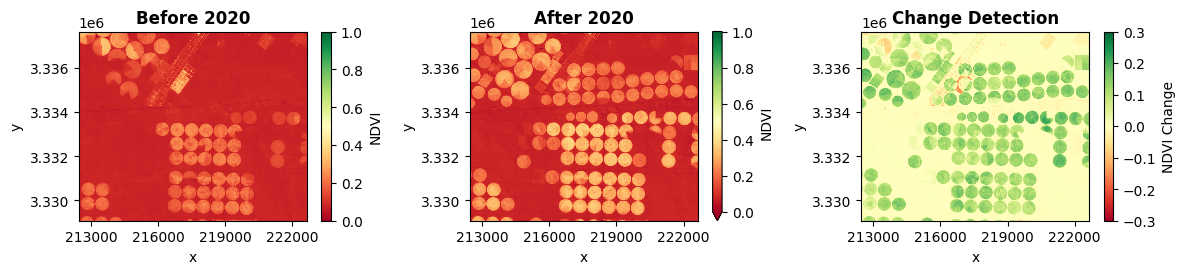

In [24]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

fig ,ax = plt.subplots(1,3,figsize=(12,3))
ndvi_2015_2020.plot(x = 'x' , y = 'y' , robust = True , vmin = 0 , vmax = 1 , cmap = 'RdYlGn', ax=ax[0])
ndvi_2020_2025.plot(x = 'x' , y = 'y' , robust = True , vmin = 0 , vmax = 1 , cmap = 'RdYlGn',ax=ax[1])
ndvi_change.plot(x = 'x' , y = 'y' , robust = True , vmin = -0.3, vmax = 0.3, cmap = 'RdYlGn',ax=ax[2], cbar_kwargs={'label': 'NDVI Change'})
ax[0].set_title('Before 2020', fontweight='bold', fontsize=12 )
ax[1].set_title('After 2020',fontweight='bold', fontsize=12)
ax[2].set_title('Change Detection',fontweight='bold', fontsize=12)
ax[0].xaxis.set_major_locator(MaxNLocator(4))
ax[1].xaxis.set_major_locator(MaxNLocator(4))
ax[2].xaxis.set_major_locator(MaxNLocator(4))
plt.tight_layout()
plt.show()